In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns
import os
import datetime
import pickle

from astropy.timeseries import LombScargle

In [3]:
if os.getcwd().endswith('/notebooks/figures'):
    os.chdir('../../')

In [4]:
from src.dataproc import utils, ccutils

### Supporting functions

In [5]:
## updated on 7/16/2026
def szred_to_responder(rednum):
    if rednum > 0.9:
        return 'SR'
    elif rednum < 0.5:
        return 'NR'
    else:
        return 'IR'

### Stimulation

In [6]:
save_flag = False

In [7]:
fname_format = 'data/RNSdata/NPEhistograms/%s_Histogram_Hourly.csv'
patcodes_path = 'data/RNSdata/Outcome/Hippo_outcomes_postprocessed_2025April08.csv'
outsupfig_dir = 'output/circpaper_figures/supp/'

# load files
patcodesdf = pd.read_csv(patcodes_path)
patient_list = ccutils.final_patient_list()

In [8]:
dfdict = {}

npe0041_date_format = "%m/%d/%y %H:%M"

for patient_id in patient_list:
    fname = fname_format %(patient_id)
    if not os.path.exists(fname):
        print(f'{patient_id}: Histogram file doesnt exist.')
        continue
        
    df = pd.read_csv(fname)
    
    if patient_id == 'NPE0041': # update the formatting of time bins for this patient
        df['Region start time'] = df['Region start time'].apply(lambda x: datetime.datetime.strptime(x, npe0041_date_format).isoformat(sep=' '))
    
    df['Local_hour'] = df['Region start time'].apply(lambda x: datetime.datetime.fromisoformat(x).hour)
    df['npe_code'] = patient_id
        
    # time from implantation
    implantdt = datetime.datetime.fromisoformat(patcodesdf.loc[patcodesdf['npe_code']==patient_id]['implant_date'].item())
    utils.tfromstart_days(df, datecol='Region start time', start_date=implantdt)
    ccutils.round_half_year_days(df)
    
    dfdict[patient_id] = df.copy()

## longitudinal analyses of stimulation

In [9]:
normtype = 'zeroone'  # 'zeroone', 'maxnorm'
lgmscdict = ccutils.mean_stimcounts(dfdict, patient_list, groupby=['dur_halfyr', 'Local_hour'], 
                                    normtype=normtype)

In [10]:
interval_start = 7   # MAGIC; change based on normtype. zeroone=7, maxnorm=5
interval_end = 11

lgaucdf = ccutils.longi_interval_aucdf(lgmscdict, patient_list, interval_start, interval_end, 
                                       verbose=True)

Dropped entries because stim AUC=0: # 9


### Supplement: Map for SPA between

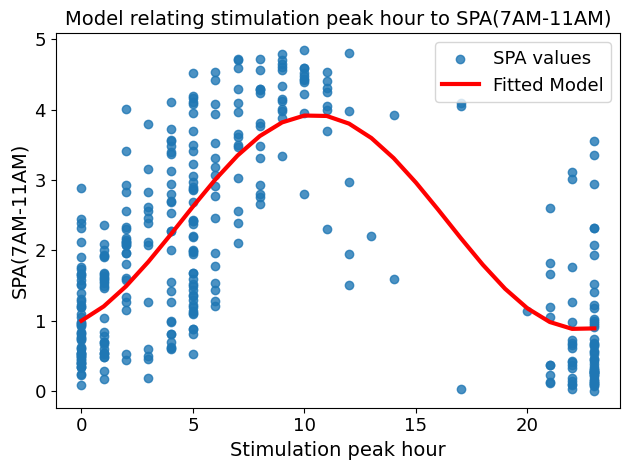

In [11]:
xvar = 'max_hour'
yvar = 'auc_interval'
time_vals = lgaucdf[xvar].values
feat_vals = lgaucdf[yvar].values

lsp_object = LombScargle(t=time_vals, y=feat_vals, fit_mean=True)
day_hour_list = np.arange(0,24)
hour_yvar_map = lsp_object.model(t=day_hour_list, frequency=1/24)

sns.regplot(data=lgaucdf, x=xvar, y=yvar, fit_reg=False, label='SPA values', x_jitter=0)
plt.plot(day_hour_list, hour_yvar_map, linewidth=3, color='red', label='Fitted Model')
plt.xlabel('Stimulation peak hour', fontsize=14)
plt.ylabel('SPA(7AM-11AM)', fontsize=14)
plt.title('Model relating stimulation peak hour to SPA(7AM-11AM)', fontsize=14)
plt.tick_params(labelsize=13)
plt.legend(fontsize=13)

plt.tight_layout()

if save_flag:
    plt.savefig(outsupfig_dir + 'insilico_hourToSPABetweenMap.pdf', dpi=300)
    
plt.show()

### Supplement: Map for AUC converse

In [12]:
aucconvmedian = lgaucdf.groupby(by='max_hour')['auc_converse'].median()

meanval = aucconvmedian.mean()   # mean of the median values for different hours
# assign mean value to missing hours
aucconvmedian[15] = meanval
aucconvmedian[16] = meanval
aucconvmedian[18] = meanval
aucconvmedian[19] = meanval

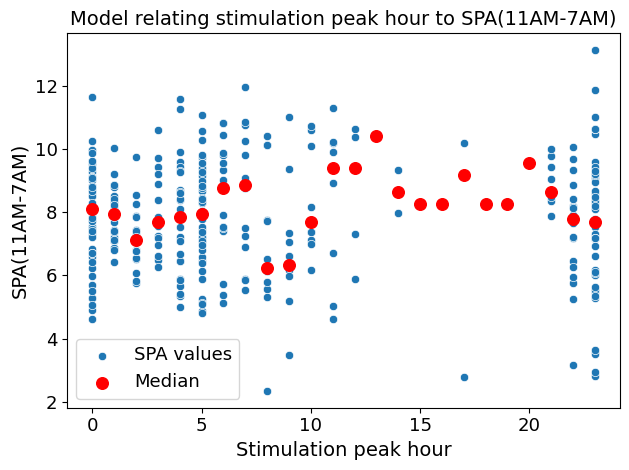

In [13]:
sns.scatterplot(data=lgaucdf, x='max_hour', y='auc_converse', label='SPA values')
plt.scatter(aucconvmedian.index.to_list(), aucconvmedian, s=70, color='red', label='Median')
plt.xlabel('Stimulation peak hour', fontsize=14)
plt.ylabel('SPA(11AM-7AM)', fontsize=14)
plt.title('Model relating stimulation peak hour to SPA(11AM-7AM)', fontsize=14)
plt.tick_params(labelsize=13)
plt.legend(fontsize=13)

plt.tight_layout()
if save_flag:
    plt.savefig(outsupfig_dir + 'insilico_hourToSPAOutsideMap.pdf', dpi=300)
    
plt.show()